# Week 3 — Classification Project: detecting malignant tumours
**Problem:** classify a breast-mass sample as **malignant (1)** or **benign (0)** from 30 image-derived measurements (Breast Cancer Wisconsin Diagnostic, UCI; 569 samples).
**Why it's a real classification problem:** a missed malignant case (false negative) is far more costly than a false alarm, so *recall on the malignant class* matters most — and accuracy alone is not enough (an "always benign" model already scores 63%).

**Plan:** stratified train/test split → scaled pipelines → compare Logistic Regression and Random Forest with cross-validation → confusion matrix + precision/recall/F1 → choose a decision threshold *without peeking at the test set* → save the final model for the Week 4 app.

In [1]:
import json, joblib, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score,
                             precision_score, recall_score, f1_score, roc_auc_score, precision_recall_curve)
sns.set_theme(style="whitegrid")

df = pd.read_csv("../data/breast_cancer_wisconsin.csv")
y = df["malignant"]
X = df.drop(columns=["malignant", "diagnosis"])
print("Class balance:", y.value_counts().to_dict(), "-> %.0f%% malignant" % (100 * y.mean()))

Class balance: {0: 357, 1: 212} -> 37% malignant


## 1. Train / test split (stratified)
`stratify=y` keeps the 63/37 class ratio identical in both sets. The test set stays untouched until the final evaluation.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("train:", X_train.shape, y_train.mean().round(3), "| test:", X_test.shape, y_test.mean().round(3))
print("'Always predict benign' accuracy on test: %.3f  <- the accuracy trap" % (1 - y_test.mean()))

train: (455, 30) 0.374 | test: (114, 30) 0.368
'Always predict benign' accuracy on test: 0.632  <- the accuracy trap


## 2. Compare two models with 5-fold cross-validation (training data only)

In [3]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42),
}
cv = StratifiedKFold(5, shuffle=True, random_state=42)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]
rows = {}
for name, m in models.items():
    r = cross_validate(m, X_train, y_train, cv=cv, scoring=scoring)
    rows[name] = {s: r[f"test_{s}"].mean() for s in scoring}
cv_table = pd.DataFrame(rows).T.round(3)
cv_table

,accuracy,precision,recall,f1,roc_auc
Logistic Regression,0.974,0.977,0.953,0.964,0.996
Random Forest,0.960,0.958,0.935,0.946,0.988


## 3. Fit on the training set and evaluate on the untouched test set

In [4]:
fitted, report = {}, []
for name, m in models.items():
    m.fit(X_train, y_train)
    fitted[name] = m
    p = m.predict(X_test)
    report.append({"model": name, "accuracy": accuracy_score(y_test, p), "precision": precision_score(y_test, p),
                   "recall": recall_score(y_test, p), "F1": f1_score(y_test, p),
                   "ROC-AUC": roc_auc_score(y_test, m.predict_proba(X_test)[:, 1])})
pd.DataFrame(report).set_index("model").round(3)

,accuracy,precision,recall,F1,ROC-AUC
model,,,,,
Logistic Regression,0.965,0.975,0.929,0.951,0.996
Random Forest,0.974,1.000,0.929,0.963,0.994


### Confusion matrices

              precision    recall  f1-score   support

      benign      0.959     0.986     0.973        72
   malignant      0.975     0.929     0.951        42

    accuracy                          0.965       114
   macro avg      0.967     0.957     0.962       114
weighted avg      0.965     0.965     0.965       114



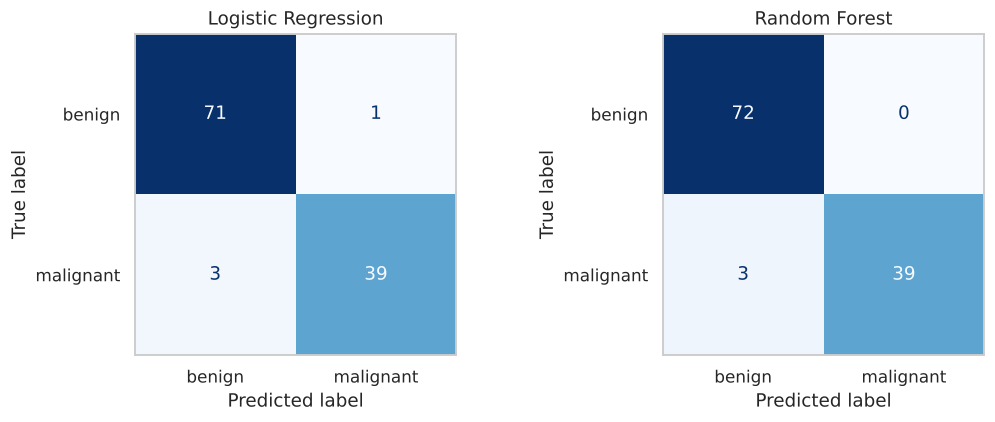

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, m) in zip(axes, fitted.items()):
    ConfusionMatrixDisplay.from_estimator(m, X_test, y_test, display_labels=["benign", "malignant"],
                                          cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name); ax.grid(False)
plt.tight_layout(); plt.show()
print(classification_report(y_test, fitted["Logistic Regression"].predict(X_test), target_names=["benign", "malignant"], digits=3))

Reading the matrix (rows = actual, columns = predicted): the bottom-left cell is the **false negatives** — malignant tumours the model called benign. That is the number we most want to push down.

## 4. Choosing the best model
The test set has only 114 samples (42 malignant), so one extra mistake moves recall by ~2 points — too noisy to pick a winner. Cross-validation on the training data (above) is the more reliable guide.

In [6]:
best_name = cv_table["f1"].idxmax()
print("Best model by cross-validated F1:", best_name)
cv_table.loc[best_name]

Best model by cross-validated F1: Logistic Regression


accuracy     0.974
precision    0.977
recall       0.953
f1           0.964
roc_auc      0.996
Name: Logistic Regression, dtype: float64

## 5. Decision threshold — chosen on training data only
The default 0.5 cut-off treats both errors equally. Because missing a malignant case is worse, I look for a lower threshold, using **out-of-fold probabilities on the training set** so the test set is not used to tune anything.

Chosen threshold: 0.3


,precision,recall,F1
threshold,,,
0.3,0.954,0.976,0.965
0.4,0.965,0.965,0.965
0.5,0.976,0.953,0.964


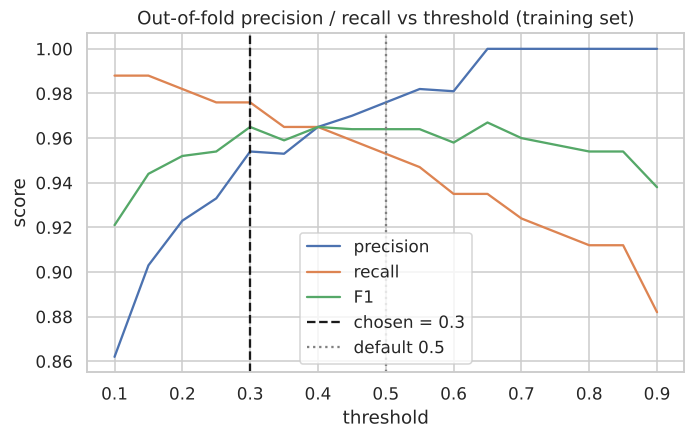

In [7]:
best = models[best_name]
oof = cross_val_predict(best, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
grid = np.round(np.arange(0.10, 0.91, 0.05), 2)
tab = pd.DataFrame({"threshold": grid,
                    "precision": [precision_score(y_train, oof >= t) for t in grid],
                    "recall": [recall_score(y_train, oof >= t) for t in grid],
                    "F1": [f1_score(y_train, oof >= t) for t in grid]}).set_index("threshold").round(3)
# rule: highest threshold that still gives >= 97% recall on out-of-fold data (best precision under that recall target)
ok = tab[tab["recall"] >= 0.97]
threshold = float(ok.index.max()) if len(ok) else 0.5
fig, ax = plt.subplots(figsize=(7, 4))
tab[["precision", "recall", "F1"]].plot(ax=ax)
ax.axvline(threshold, color="k", ls="--", label=f"chosen = {threshold}")
ax.axvline(0.5, color="grey", ls=":", label="default 0.5")
ax.set(title="Out-of-fold precision / recall vs threshold (training set)", ylabel="score"); ax.legend()
plt.show()
print("Chosen threshold:", threshold)
tab.loc[[0.3, 0.4, 0.5]] if {0.3, 0.4, 0.5} <= set(tab.index) else tab

## 6. Final test-set evaluation (threshold applied once)

,TN,FP,FN,TP,accuracy,precision,recall,F1
threshold,,,,,,,,
default 0.5,71,1,3,39,0.965,0.975,0.929,0.951
chosen 0.3,71,1,1,41,0.982,0.976,0.976,0.976


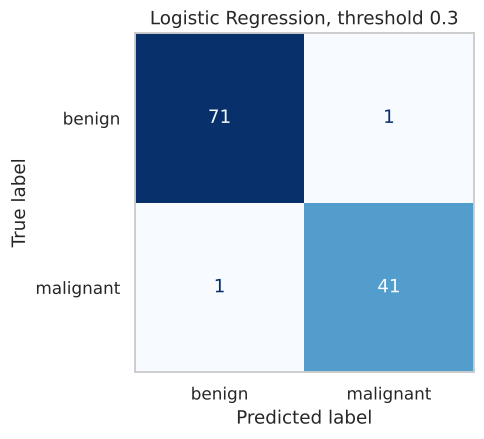

In [8]:
final = models[best_name].fit(X_train, y_train)
proba = final.predict_proba(X_test)[:, 1]
rows = []
for label, t in [("default 0.5", 0.5), (f"chosen {threshold}", threshold)]:
    p = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, p).ravel()
    rows.append({"threshold": label, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
                 "accuracy": accuracy_score(y_test, p), "precision": precision_score(y_test, p),
                 "recall": recall_score(y_test, p), "F1": f1_score(y_test, p)})
final_table = pd.DataFrame(rows).set_index("threshold").round(3)
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, (proba >= threshold).astype(int), display_labels=["benign", "malignant"],
                                        cmap="Blues", colorbar=False, ax=ax)
ax.set_title(f"{best_name}, threshold {threshold}"); ax.grid(False); plt.show()
final_table

## 7. What does the model use?

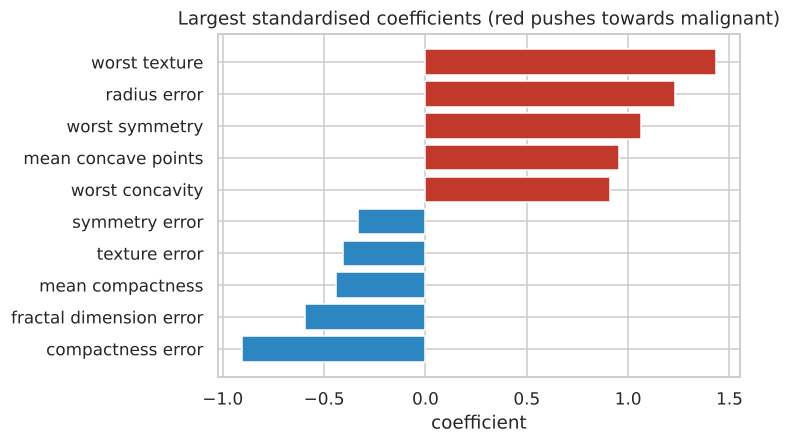

In [9]:
coef = pd.Series(final[-1].coef_[0], index=X.columns).sort_values()
top = pd.concat([coef.head(5), coef.tail(5)])
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(top.index, top.values, color=["#2e86c1" if v < 0 else "#c0392b" for v in top.values])
ax.set(title="Largest standardised coefficients (red pushes towards malignant)", xlabel="coefficient")
plt.tight_layout(); plt.show()

## 8. Save the final model for the Week 4 app

In [10]:
import os
os.makedirs("../week4-streamlit-app/model", exist_ok=True)
stats = X_train.describe().T
meta = {"model": best_name, "threshold": threshold, "target": "malignant (1) / benign (0)",
        "features": list(X.columns),
        "feature_stats": {f: {"min": float(stats.loc[f, "min"]), "mean": float(stats.loc[f, "mean"]),
                              "max": float(stats.loc[f, "max"])} for f in X.columns},
        "test_metrics": final_table.loc[f"chosen {threshold}"].to_dict()}
joblib.dump(final, "../week4-streamlit-app/model/model.joblib")
json.dump(meta, open("../week4-streamlit-app/model/model_meta.json", "w"), indent=2, default=float)
print("saved model + metadata; threshold =", threshold)

saved model + metadata; threshold = 0.3


## 9. Results write-up

**Setup.** 569 samples, 30 features, stratified 80/20 split (455 train / 114 test; 42 malignant in test). Logistic Regression (with scaling) vs Random Forest.

| Cross-validated (train, 5-fold) | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| **Logistic Regression** | 0.974 | 0.977 | 0.953 | **0.964** | 0.996 |
| Random Forest | 0.960 | 0.958 | 0.935 | 0.946 | 0.988 |

Logistic Regression was selected: it wins on every cross-validated metric, is far smaller and faster, and its coefficients are explainable. (On the single small test split the two are within one patient of each other, which is exactly why cross-validation decides.)

**Final model on the held-out test set**

| Threshold | TN | FP | FN | TP | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|---|---|---|---|
| 0.5 (default) | 71 | 1 | 3 | 39 | 0.965 | 0.975 | 0.929 | 0.951 |
| **0.3 (chosen)** | 71 | 1 | **1** | 41 | **0.982** | 0.976 | **0.976** | **0.976** |

- **Accuracy is not the headline.** An "always benign" model scores 63% accuracy while catching zero cancers; that is why precision, recall and F1 are reported for the malignant class.
- **Threshold choice.** The threshold of 0.3 was picked from out-of-fold predictions on the *training* data (highest threshold keeping recall ≥ 97%), then applied once to the test set. It cut missed malignant cases from 3 to 1 without adding any false alarms.
- **Reading the errors.** At 0.3 the model misses 1 of 42 malignant samples (false negative) and wrongly flags 1 of 72 benign ones (false positive).
- **Drivers.** Positive coefficients (towards malignant) are led by `worst_texture`, `radius_error`, `worst_symmetry`, `mean_concave_points` and `worst_concavity`; the largest negative ones are `compactness_error` and `fractal_dimension_error`. Because features are correlated (Week 1), individual coefficients should be read as a group effect, not as isolated causes.

**Limitations.** Only 114 test samples: one patient shifts recall by ~2.4 points, so these numbers carry real uncertainty (a confidence interval would be wide). The data comes from one source; performance on other hospitals' images is unknown. This is a learning project, **not a diagnostic tool**.

**Next steps.** Repeated cross-validation for tighter estimates, calibration of probabilities, trying gradient boosting, and testing on an external dataset.